# 06 — Evaluación e interpretación final del modelo

## ¿Qué voy a hacer en este notebook?

Voy a evaluar el Random Forest ya entrenado sobre el periodo `test`, que representa transacciones posteriores a las usadas para aprender y seleccionar el umbral. La referencia temporal es `step`: en PaySim cada `step` corresponde a **una hora simulada**.

Aquí `step` solo me permite comprobar el modelo en horas posteriores; no fue usado como señal para predecir fraude. Este es el momento en que puedo responder si mi propuesta mejora la priorización frente a `isFlaggedFraud`.

No volveré a entrenar ni ajustar el umbral mirando los resultados de prueba.

In [1]:
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'paysim.csv'
IMAGES_DIR = PROJECT_ROOT / 'images'
REPORTS_DIR = PROJECT_ROOT / 'reports'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUTS_DIR = PROJECT_ROOT / 'data' / 'outputs'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
for folder in [IMAGES_DIR, REPORTS_DIR, MODELS_DIR, OUTPUTS_DIR, PROCESSED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


In [2]:
import pandas as pd
from modeling_utils import (
    ALERT_COLUMN, CATEGORICAL_FEATURES, MODEL_FEATURES, NUMERIC_FEATURES, TARGET,
    TRAIN_END_STEP, VALIDATION_END_STEP, engineer_features, load_transactions,
    split_summary, temporal_split, training_sample, xy,
)

raw = load_transactions(DATA_RAW)
data = engineer_features(raw)
train, validation, test = temporal_split(data)
summary = split_summary(train, validation, test)
summary


,transacciones,fraudes,tasa_fraude_pct,step_min,step_max
periodo,,,,,
train,4463587,3643,0.0816,1,323
validation,980416,564,0.0575,324,378
test,918617,4006,0.4361,379,743


## Recuperar la decisión tomada en entrenamiento

Cargo el modelo y el umbral guardados por el notebook 05. La prueba temporal permanece completa: no quito operaciones legítimas, porque necesito medir el costo real de las alertas falsas.

In [4]:
import joblib  # Carga y guarda objetos de Python serializados en disco

model_path = MODELS_DIR / 'random_forest_fraud.joblib'  # Ruta donde se espera el modelo entrenado

if not model_path.exists():  # Verifica si el archivo del modelo existe
    raise FileNotFoundError('Primero ejecuta 05_modeling.ipynb para generar el modelo.')  # Detiene la ejecución si no está

bundle = joblib.load(model_path)  # Carga el diccionario guardado con el modelo y sus parámetros

model = bundle['model']  # Extrae el modelo entrenado
threshold = bundle['threshold']  # Extrae el umbral de decisión definido en validación

X_test, y_test = xy(test)  # Separa el conjunto test en variables predictoras y etiqueta real

test_probability = model.predict_proba(X_test)[:, 1]  # Calcula la probabilidad de fraude para cada transacción

print(f'Test futuro: {len(test):,} transacciones | {int(y_test.sum()):,} fraudes')  # Resume el tamaño y fraudes reales
print(f'Umbral congelado desde validation: {threshold:.6f}')  # Muestra el umbral fijo usado para decidir alertas

Test futuro: 918,617 transacciones | 4,006 fraudes
Umbral congelado desde validation: 0.858498


## Métricas que sí importan en fraude

No tomaré `accuracy` como conclusión principal: con tantas operaciones normales, un sistema que no detecte fraudes podría parecer acertado. Interpreto:

- **Recall:** de todos los fraudes, cuántos logro marcar.
- **Precisión:** de todas mis alertas, cuántas eran fraude.
- **F2:** balance que da más importancia a capturar fraudes.
- **Average Precision:** calidad del ranking de probabilidades ante el desbalance.
- **Monto detectado:** dinero fraudulento que habría quedado priorizado para revisión.

In [5]:
model_metrics = metric_summary(test, test_probability, threshold, 'Random Forest propuesto')
original_metrics = original_alert_summary(test)
comparison = pd.DataFrame([model_metrics, original_metrics]).set_index('regla')
comparison[['precision', 'recall', 'f2', 'average_precision', 'verdaderos_positivos', 'falsos_positivos', 'falsos_negativos', 'monto_detectado_pct']]

,precision,recall,f2,average_precision,verdaderos_positivos,falsos_positivos,falsos_negativos,monto_detectado_pct
regla,,,,,,,,
Random Forest propuesto,1.0,0.997254,0.997802,0.999986,3995,0,11,99.044997
Alerta original isFlaggedFraud,1.0,0.003245,0.004053,0.007592,13,0,3993,1.122118


## Matriz de confusión y curva precisión-recall

La matriz permite ver explícitamente fraudes detectados y omitidos. La curva muestra cómo cambia el compromiso entre capturar más fraude y generar más revisiones al mover el umbral.

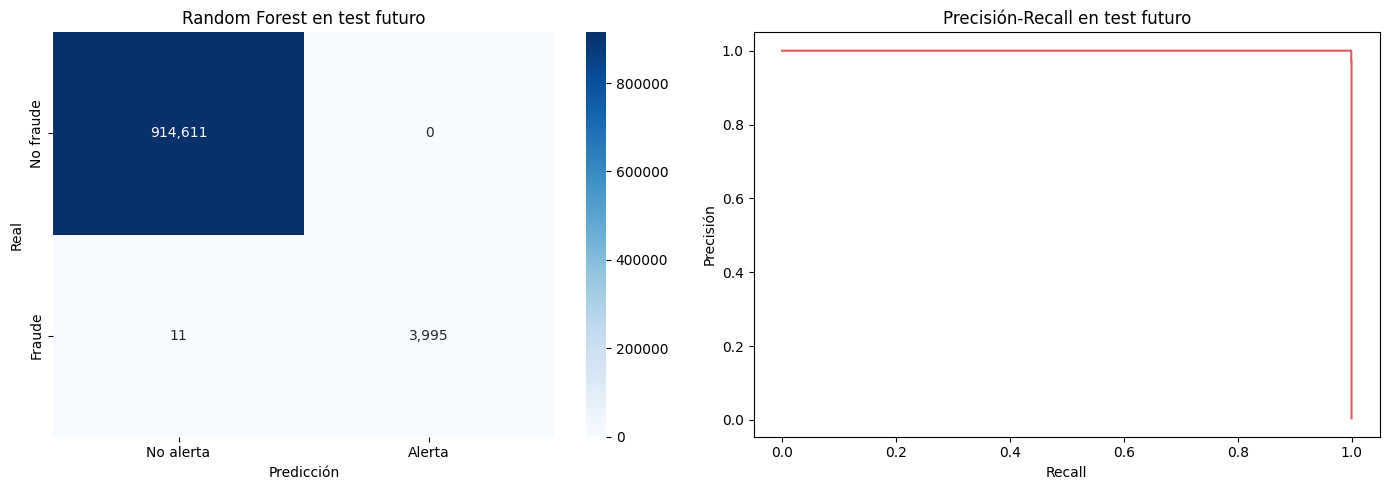

Gráfico guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/model_test_evaluation.png


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_curve

prediction = (test_probability >= threshold).astype('int8')
cm = confusion_matrix(y_test, prediction, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=axes[0], xticklabels=['No alerta', 'Alerta'], yticklabels=['No fraude', 'Fraude'])
axes[0].set_title('Random Forest en test futuro')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')
precision, recall, _ = precision_recall_curve(y_test, test_probability)
axes[1].plot(recall, precision, color='#e45756')
axes[1].set_title('Precisión-Recall en test futuro')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precisión')
plt.tight_layout()
evaluation_plot = IMAGES_DIR / 'model_test_evaluation.png'
plt.savefig(evaluation_plot, bbox_inches='tight')
plt.show()
print('Gráfico guardado:', evaluation_plot)

## Impacto económico y comparación con la alerta existente

Además del conteo, comparo cuánto monto fraudulento logra marcar cada regla. Esta lectura conecta el modelo con la pregunta de negocio original: cuánto dinero riesgoso podría priorizarse.

In [6]:
business_comparison = comparison[[
    'verdaderos_positivos', 'falsos_negativos', 'falsos_positivos',
    'monto_fraude_detectado', 'monto_fraude_total', 'monto_detectado_pct'
]].copy()
business_comparison

,verdaderos_positivos,falsos_negativos,falsos_positivos,monto_fraude_detectado,monto_fraude_total,monto_detectado_pct
regla,,,,,,
Random Forest propuesto,3995,11,0,6.262661e+09,6.323047e+09,99.044997
Alerta original isFlaggedFraud,13,3993,0,7.095204e+07,6.323047e+09,1.122118


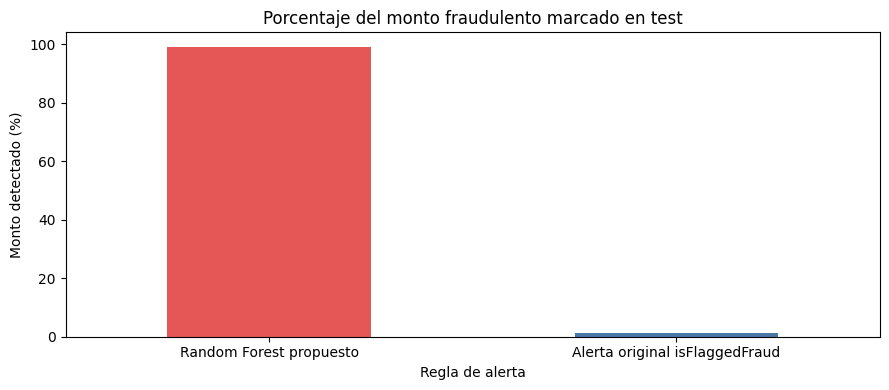

Gráfico guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/model_detected_amount_comparison.png


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
business_comparison['monto_detectado_pct'].plot.bar(ax=ax, color=['#e45756', '#4c78a8'])
ax.set_title('Porcentaje del monto fraudulento marcado en test')
ax.set_ylabel('Monto detectado (%)')
ax.set_xlabel('Regla de alerta')
plt.xticks(rotation=0)
plt.tight_layout()
amount_plot = IMAGES_DIR / 'model_detected_amount_comparison.png'
plt.savefig(amount_plot, bbox_inches='tight')
plt.show()
print('Gráfico guardado:', amount_plot)

## Interpretación responsable

Este resultado mide un ejercicio reproducible sobre PaySim, un dataset sintético. Como uso saldos posteriores a la operación, la conclusión aplica a priorizar revisión posterior, no a impedir la transacción antes de que ocurra. Un uso real requeriría datos reales, calibración, costos de falsas alertas, monitoreo de deriva y validación regulatoria.

**Advertencia sobre métricas muy altas:** PaySim puede contener patrones simulados más separables que los de un banco real. Por eso, un recall cercano al 100% aquí no demuestra que el mismo modelo funcionaría así en producción.

In [8]:
report_path = REPORTS_DIR / 'model_evaluation_report.md'
model_recall = model_metrics['recall'] * 100
alert_recall = original_metrics['recall'] * 100
model_amount = model_metrics['monto_detectado_pct']
alert_amount = original_metrics['monto_detectado_pct']
content = '\n'.join([
    '# Reporte de evaluación del modelo de fraude — PaySim (Parte 2)',
    '',
    '## Qué hice',
    '',
    'Entrené un único `RandomForestClassifier` con datos anteriores y elegí su umbral en validación. Luego evalué el periodo futuro reservado sin modificar el modelo.',
    '',
    '## Por qué escogí este modelo',
    '',
    'Escogí Random Forest porque el objetivo es una clasificación binaria, las señales del EDA pueden interactuar de forma no lineal y el modelo permite ponderar la clase fraudulenta e interpretar importancias.',
    '',
    '## Resultados en test futuro',
    '',
    comparison.to_string(),
    '',
    '## Conclusión',
    '',
    f'- Mi modelo detectó {model_metrics["verdaderos_positivos"]:.0f} fraudes de {int(test[TARGET].sum())} (recall {model_recall:.2f}%).',
    f'- La alerta original detectó {original_metrics["verdaderos_positivos"]:.0f} fraudes en el mismo periodo (recall {alert_recall:.2f}%).',
    f'- Mi modelo priorizó {model_amount:.2f}% del monto fraudulento; la alerta original priorizó {alert_amount:.2f}%.',
    '',
    '## Límite de interpretación',
    '',
    'Este resultado es educativo y usa datos sintéticos. Incluye saldos posteriores, por lo que corresponde a revisión post-transacción y no a autorización previa en producción.',
    '',
    'Un desempeño muy alto puede deberse a patrones simulados de PaySim y a la disponibilidad de saldos posteriores; no demuestra rendimiento equivalente en datos bancarios reales.',
])
report_path.write_text(content + '\n', encoding='utf-8')
print('Reporte guardado:', report_path)
print(
    f'Conclusión final: en el periodo futuro, mi Random Forest alcanzó recall de {model_recall:.2f}% '
    f'y priorizó {model_amount:.2f}% del monto fraudulento, frente a {alert_recall:.2f}% de recall '
    f'y {alert_amount:.2f}% del monto con la alerta original.'
)

Reporte guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/reports/model_evaluation_report.md
Conclusión final: en el periodo futuro, mi Random Forest alcanzó recall de 99.73% y priorizó 99.04% del monto fraudulento, frente a 0.32% de recall y 1.12% del monto con la alerta original.


## Cierre del proyecto

Con este notebook cierro la Parte 2: pasé de entender el fraude a construir y evaluar una alternativa de priorización. Mis conclusiones deben leerse junto con las limitaciones metodológicas documentadas y no como autorización para desplegar el modelo en un banco real.